# XAI with MLP-RBFKAN on California housing dataset

## Import

In [1]:
from mlp_rbf_kan.models import MLP_RBFKAN, MLP, train_regression
from mlp_rbf_kan.datasets import load_california_housing_dataset
from mlp_rbf_kan.eval.tools import *
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
import shap

c:\Users\garem\miniconda3\envs\kan\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dataset = load_california_housing_dataset()

housing = fetch_california_housing()
feature_names = housing.feature_names

print(feature_names)

California Housing ready! Features: 8
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## XAI analysis

In [3]:
def plot_feature_importance(model, x_data, feature_names):
    model.eval()
    x_data.requires_grad = True
    
    output = model(x_data)
    dummy_target = torch.ones_like(output)
    output.backward(gradient=dummy_target)
    
    importances = x_data.grad.abs().mean(dim=0).cpu().numpy()
    
    indices = np.argsort(importances)
    plt.figure(figsize=(10, 6))
    plt.title("XAI: Feature Importance Globale (Gradients)")
    plt.barh(range(len(indices)), importances[indices], align='center')
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel('Importanza Relativa')
    plt.show()

In [13]:
def plot_pdp_ice(model, x_data, feature_idx, feature_name, n_samples=50, n_points=50):
    # Rileva il dispositivo su cui si trova il modello
    # Assumiamo che il primo parametro del modello ci dica dove si trova
    device = next(model.parameters()).device
    model.eval()

    indices = np.random.choice(len(x_data), n_samples, replace=False)
    x_subset = x_data[indices]
    
    f_min, f_max = x_data[:, feature_idx].min(), x_data[:, feature_idx].max()
    x_range = torch.linspace(f_min, f_max, n_points, device=device)
    
    plt.figure(figsize=(10, 6))
    
    ice_lines = []
    for i in range(n_samples):
        x_rep = x_subset[i].unsqueeze(0).repeat(n_points, 1).to(device)
        x_rep[:, feature_idx] = x_range
        
        with torch.no_grad():
            preds = model(x_rep).cpu().numpy()
        
        ice_lines.append(preds)
        plt.plot(x_range.cpu().numpy(), preds, color='gray', alpha=0.3, lw=0.5)

    pdp_line = np.mean(np.array(ice_lines), axis=0)
    plt.plot(x_range.cpu().numpy(), pdp_line, color='red', lw=3, label='PDP (Avg)')
    
    plt.title(f"XAI: PDP & ICE Plot for: {feature_name}")
    plt.xlabel(f"{feature_name}")
    plt.ylabel("Prediction")
    plt.legend()
    plt.grid(True, alpha=0.2)
    plt.show()

## Training

In [5]:
# Hyperparameters
input_dim = dataset['train_input'].shape[1] # 8 features
hidden_dim = 32
output_dim = 1
num_centers = 8
domain = (-2.0, 2.0)

mlp = MLP(
    input_dim,
    hidden_dim,
    output_dim
)

mlp_rbf_kan = MLP_RBFKAN(
    in_dim=input_dim, 
    hidden_dim=hidden_dim, 
    out_dim=output_dim, 
    num_centers=num_centers, 
    domain=domain,
    enable_silu=True
).to(device)

In [6]:
train_loss_mlp, test_loss_mlp, mlp_preds = train_regression(
    mlp,
    dataset['train_input'], dataset['train_label'],
    dataset['test_input'], dataset['test_label'],
    epochs=100,
    lr=0.001,              
    optimizer_type="adam", 
    batch_size=256,
    update_grid_every=10,
    weight_decay=0.0001
)

train_loss_rbfkan, test_loss_rbfkan, rbfkan_preds = train_regression(
    mlp_rbf_kan,
    dataset['train_input'], dataset['train_label'],
    dataset['test_input'], dataset['test_label'],
    epochs=100,
    lr=1.0,              
    optimizer_type="lbfgs", 
    batch_size=256,
    update_grid_every=10 ,
    weight_decay=0.0001
)

| [Model] | train RMSE: 0.6637 | test RMSE: 0.6737 |: 100%|██████| 100/100 [00:00<00:00, 106.05it/s]
| [Model] | train RMSE: 0.4166 | test RMSE: 0.4427 |: 100%|███████| 100/100 [00:22<00:00,  4.48it/s]


## XAI analysis and considerations

### Loss trend

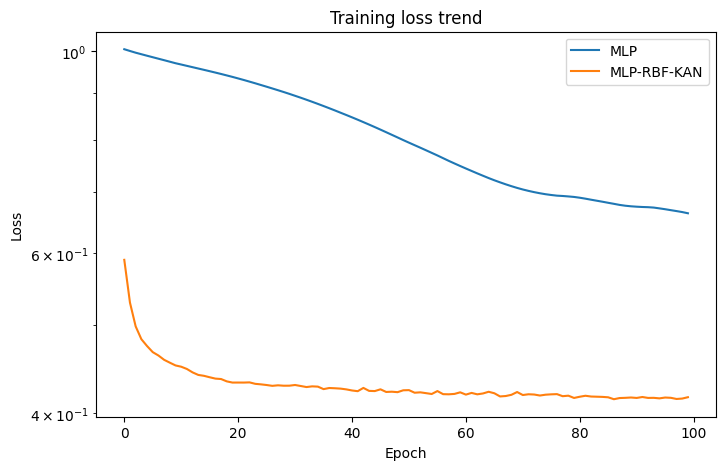

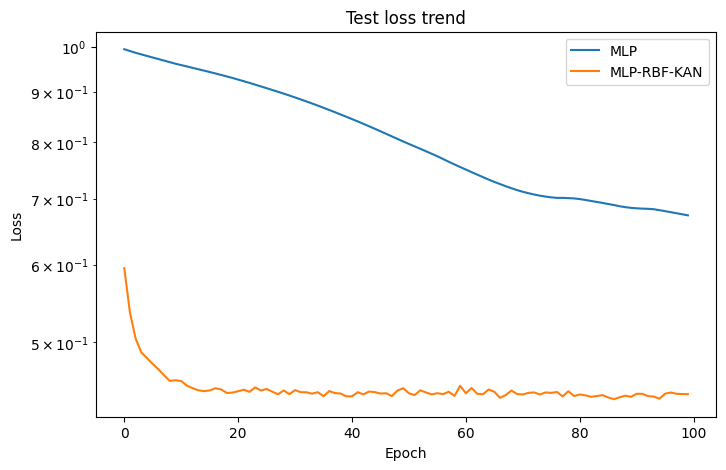

Final loss [MLP]: 0.6737112402915955
Final loss [MLP+RBF-KAN]: 0.44272372126579285


In [7]:
plot_losses({
    "MLP": train_loss_mlp,
    "MLP-RBF-KAN": train_loss_rbfkan
},"Training loss trend") 

plot_losses({
    "MLP": test_loss_mlp,
    "MLP-RBF-KAN": test_loss_rbfkan
},"Test loss trend") 

print(f"Final loss [MLP]: {test_loss_mlp[-1]}")
print(f"Final loss [MLP+RBF-KAN]: {test_loss_rbfkan[-1]}")

### Feature importance

The gradient-based importance technique belongs to the category of global explanation methods based on sensitivity analysis.

- **Description**: This method calculates the partial derivative of the output with respect to each input variable through backpropagation.
- **Measurement**: It quantifies the average sensitivity of the model to infinitesimal variations in each feature.
- **XAI Objective**: To establish an influence hierarchy, identifying which variables contribute most to the variance of predictions across the entire dataset.

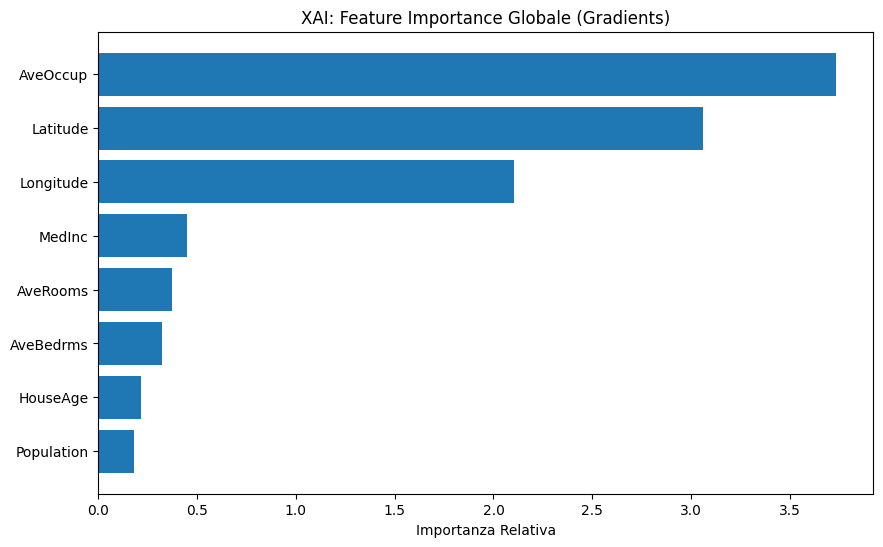

In [8]:
plot_feature_importance(mlp_rbf_kan, dataset['test_input'].to(device), dataset['feature_names'])

### RBF actiavtion functions and paremeters

This tool analyzes the internal architecture of the RBF-KAN layer by visualizing the basis functions learned during the optimization process.

- **Description**: Radial Basis Functions act as local activators, defining the neuron's response based on the proximity of the input to a specific center.
- **Measurement**: It identifies the distribution of centers and the amplitude (scale) of local responses for each individual input variable.
- **XAI Objective**: To provide a visual decomposition of the model's non-linearity, showing how the overall activation function is constructed through a weighted sum of local contributions.

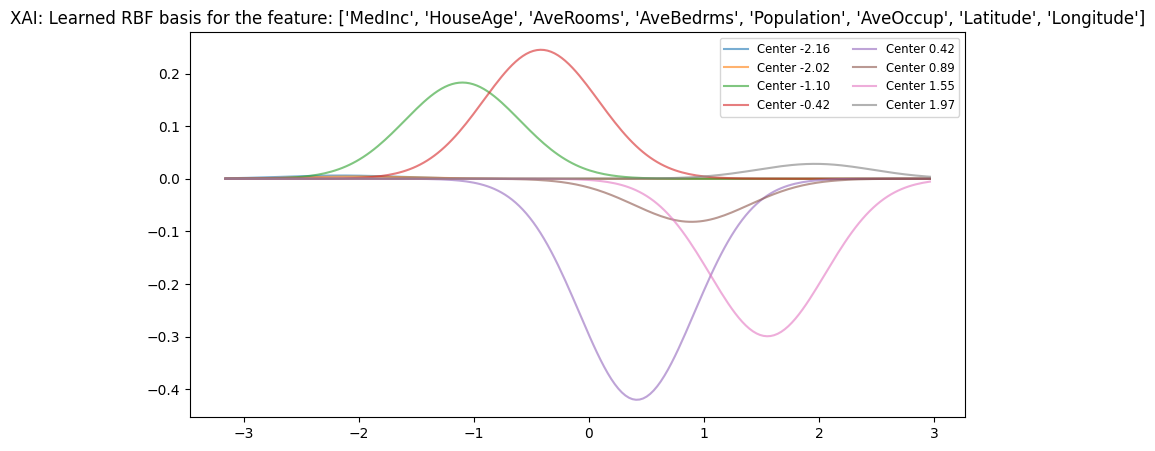

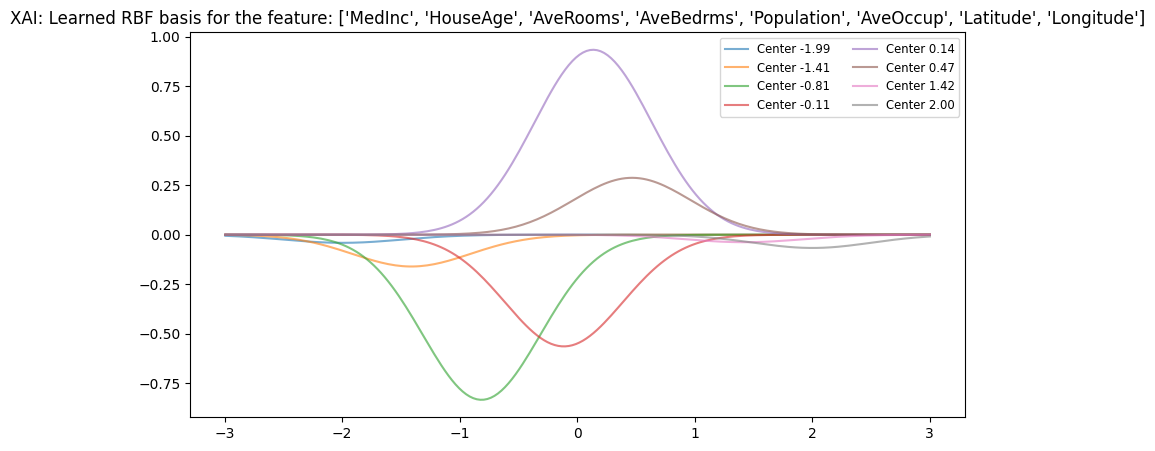

MLP number of parameters: 1377
MLP with RBF-KAN number of parameters: 2049


In [9]:
visualize_rbf_activations(mlp_rbf_kan.act1, dataset["feature_names"])
visualize_rbf_activations(mlp_rbf_kan.act2, dataset["feature_names"])

print(f"MLP number of parameters: {n_parameters(mlp)}")
print(f"MLP with RBF-KAN number of parameters: {n_parameters(mlp_rbf_kan)}")

### PDP and ICE plots

These plots analyze the functional relationship between input and output by isolating the effect of a single variable.

- **Description**: The PDP represents the average marginal effect of a feature on the target variable, while ICE curves show this relationship for individual samples.
- **Measurement**: The PDP highlights global trends (linear, monotonic, or complex), while ICE curves reveal the presence of interactions between variables.
- **XAI Objective**: To validate the local nature of RBF activations and identify regions of instability or plateaus in the model's response.

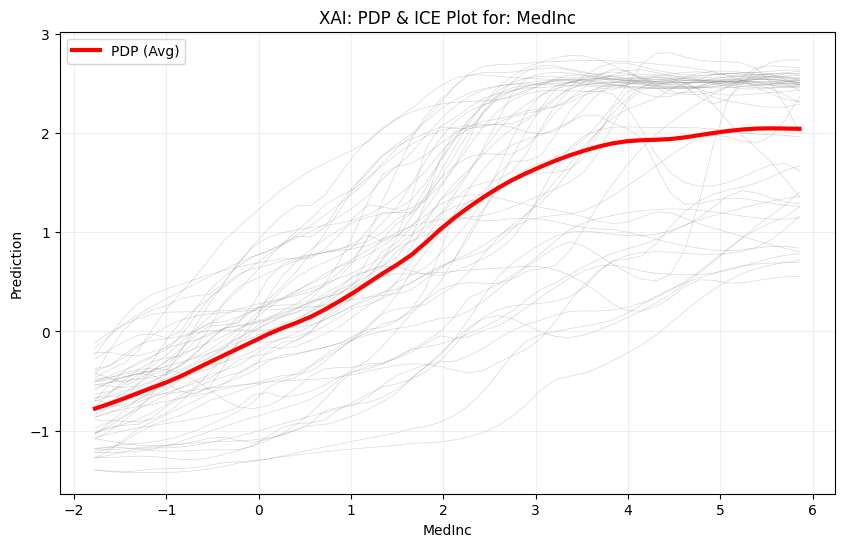

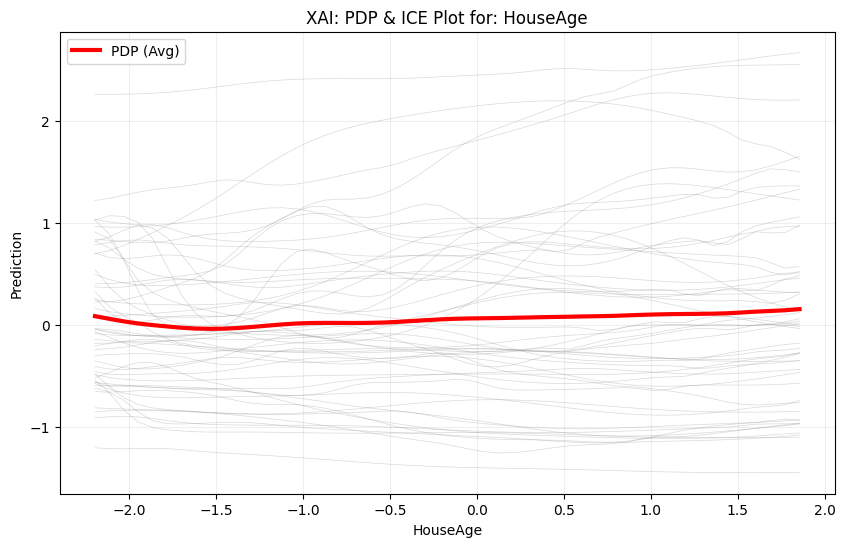

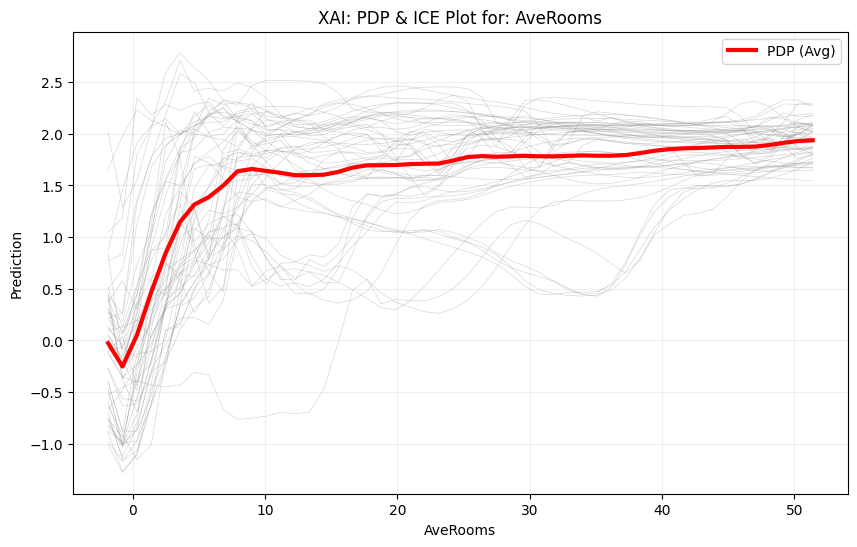

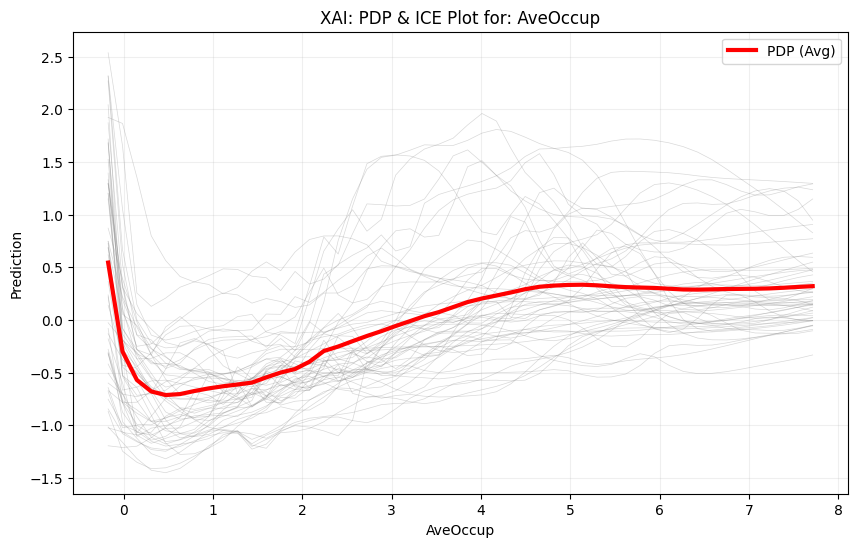

In [15]:
# PDP and ICE plot
for i in [0, 1, 2, 5]:
    plot_pdp_ice(
        model=mlp_rbf_kan, 
        x_data=dataset['test_input'], 
        feature_idx=i, 
        feature_name=feature_names[i]
    )

### SHAP values

Based on cooperative game theory, SHAP provides a unified framework for interpreting the predictions of machine learning models.

- **Description**: It assigns an importance value (Shapley value) to each feature for a specific prediction, ensuring properties of additivity and fairness in contribution distribution.
- **Measurement**: It simultaneously visualizes importance, data density, and the direction of impact (positive or negative) for each feature.
- **XAI Objective**: To provide a comprehensive view of feature impact that surpasses the limits of simple gradient analysis, showing how high or low input values influence the final result.

In [ ]:
def compute_shap_analysis(
    model,
    dataset,
    n_background=50,
    n_test=50,
    nsamples=100
):
    """
    Calcola SHAP values per un modello PyTorch (MLP + RBF/KAN)

    Returns:
        explainer
        shap_values
        X_test
        feature_names
    """

    model.eval()
    model.to("cpu")

    # ---- Wrapper NumPy → PyTorch ----
    def model_predict_numpy(x_numpy):
        x_tensor = torch.tensor(x_numpy, dtype=torch.float32)
        with torch.no_grad():
            output = model(x_tensor)
        return output.numpy()

    # ---- Background (train) ----
    train_data = dataset["train_input"].detach().cpu().numpy()
    bg_idx = np.random.choice(train_data.shape[0], n_background, replace=False)
    background = train_data[bg_idx]

    # ---- Campioni da spiegare (test) ----
    test_data = dataset["test_input"].detach().cpu().numpy()
    X_test = test_data[:n_test]

    # ---- KernelExplainer ----
    explainer = shap.KernelExplainer(
        model_predict_numpy,
        background
    )

    print("SHAP values computation...")
    shap_values = explainer.shap_values(
        X_test,
        nsamples=nsamples
    )
    
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    return explainer, shap_values, X_test, dataset["feature_names"]

In [ ]:
explainer, shap_values, X_test, features = compute_shap_analysis(mlp_rbf_kan, dataset)

In [ ]:
# =========================================
# SHAP Summary Dot Plot
# =========================================
def shap_summary_plot(shap_values, X, feature_names):
    if isinstance(shap_values, list):
        shap_values = shap_values[0]
    
    if shap_values.ndim == 3 and shap_values.shape[2] == 1:
        shap_values = shap_values.squeeze(2)
    
    # Plot
    shap.summary_plot(
        shap_values,
        X,
        feature_names=feature_names,
        max_display=len(feature_names),
        show=True
    )

# =========================================
# SHAP Dependence Plot
# =========================================
def shap_dependence_plot(shap_values, X, feature_names, feature_name, interaction="auto"):
    """
    Dependence plot for KernelExplainer regression.
    """

    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    # Se ha dimensione extra (n_samples, n_features, 1)
    if shap_values.ndim == 3 and shap_values.shape[2] == 1:
        shap_values = shap_values.squeeze(2) 

    if shap_values.ndim != 2:
        raise ValueError(f"shap_values must be 2D. Current shape: {shap_values.shape}")
    
    feature_idx = feature_names.index(feature_name)

    # Plot
    shap.dependence_plot(
        feature_idx,
        shap_values,
        X,
        feature_names=feature_names,
        interaction_index=interaction,
        show=True
    )


# =========================================
# SHAP Waterfall Plot
# =========================================
def shap_waterfall_plot(explainer, shap_values, X, feature_names, sample_idx=0):
    """
    Waterfall plot for KernelExplainer regression.
    """
    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    if shap_values.ndim == 3 and shap_values.shape[2] == 1:
        shap_values = shap_values.squeeze(2) 

    sample_values = shap_values[sample_idx]
    sample_data = X[sample_idx]

    expl = shap.Explanation(
        values=sample_values,
        base_values=explainer.expected_value,
        data=sample_data,
        feature_names=feature_names
    )
    shap.plots.waterfall(expl)


# =========================================
# SHAP Force Plot
# =========================================
def shap_force_plot(explainer, shap_values, X, feature_names, sample_idx=0):
    """
    Interactive Force plot for KernelExplainer regression.
    """
    shap.initjs()

    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    if shap_values.ndim == 3 and shap_values.shape[2] == 1:
        shap_values = shap_values.squeeze(2)

    sample_values = shap_values[sample_idx]  # 1D
    sample_data = X[sample_idx]              # 1D

    return shap.force_plot(
        explainer.expected_value,
        sample_values,
        sample_data,
        feature_names=feature_names
    )

In [ ]:
# Shap values computation
explainer, shap_values, X_test, feature_names = compute_shap_analysis(mlp_rbf_kan, dataset)

# Summary Dot Plot
shap_summary_plot(shap_values, X_test, feature_names)

# Dependence Plot
shap_dependence_plot(shap_values, X_test, feature_names, "MedInc")

# Waterfall Plot
shap_waterfall_plot(explainer, shap_values, X_test, feature_names, sample_idx=3)

# 6️⃣ Force Plot interattivo (Jupyter)
shap_force_plot(explainer, shap_values, X_test, feature_names, sample_idx=3)